# Week 13 Mini Assignment — PySpark Data Processing Pipeline
**Dataset:** NYC TLC Yellow Taxi trip records, Feb 2023 – Dec 2024 (23 monthly Parquet files, ~1.2 GB on disk, ~70M rows)
joined with the TLC *Taxi Zone Lookup* table (265 rows).

**Sections**
1. Dataset selection & loading
2. Transformation pipeline (filters, `withColumn`, join, `groupBy`, window)
3. Actions vs. transformations (lazy vs. eager)
4. Writing output (partitioned Parquet)
5. Spark SQL queries
6. Optimization & performance analysis (`.explain()`, pushdown, pruning, broadcast join)
7. Caching (`.cache()`) — bonus
8. MLlib regression — optional
9. Key findings

In [1]:
import os, time, glob, json, contextlib, io, urllib.request
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from pyspark.sql import SparkSession, functions as F, Window

BASE      = os.getcwd()
DATA      = os.environ.get("TAXI_DATA", f"{BASE}/data/yellow")
ZONES_CSV = f"{BASE}/data/taxi_zone_lookup.csv"
OUT       = os.environ.get("OUT_DIR", f"{BASE}/output")
EVENTS    = os.environ.get("EVENT_DIR", f"{BASE}/spark-events")
IMG       = f"{BASE}/images"
for d in (OUT, EVENTS, IMG): os.makedirs(d, exist_ok=True)

spark = (SparkSession.builder
         .appName("Week13-NYC-Taxi-PySpark")
         .master("local[8]")
         .config("spark.driver.memory", "5g")
         .config("spark.sql.shuffle.partitions", "32")
         .config("spark.sql.adaptive.enabled", "true")          # AQE (default in 3.2+, explicit for clarity)
         .config("spark.eventLog.enabled", "true")               # so the History Server can show Query Details later
         .config("spark.eventLog.dir", f"file://{EVENTS}")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
print("Spark", spark.version, "| app id:", sc.applicationId, "| UI:", sc.uiWebUrl)

results = []      # (label, seconds) -> used in the performance summary
def timed(label, fn, runs=1):
    """Run fn() `runs` times, tag the Spark jobs with `label` (shows up in the Spark UI SQL tab), keep the best time."""
    sc.setJobDescription(label)
    best, out, all_t = None, None, []
    for _ in range(runs):
        t = time.perf_counter(); out = fn(); dt = time.perf_counter() - t
        all_t.append(dt); best = dt if best is None else min(best, dt)
    results.append((label, best))
    print(f"⏱  {label}: {best:.2f}s" + (f"  (runs: {', '.join(f'{x:.2f}s' for x in all_t)})" if runs > 1 else ""))
    return out

def plan_lines(df, keys=("PushedFilters", "ReadSchema", "PartitionFilters", "BroadcastHashJoin",
                         "SortMergeJoin", "Exchange", "BroadcastExchange", "FileScan", "Scan parquet")):
    """Capture df.explain('formatted') and return only the interesting lines."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain(mode="formatted")
    lines = [l.strip() for l in buf.getvalue().splitlines()]
    keep = [l for l in lines if l.startswith(("PushedFilters", "ReadSchema", "PartitionFilters")) or "Join" in l]
    n_shuffle = sum(1 for l in lines if l.startswith("(") and " Exchange" in l and "Broadcast" not in l)
    return "\n".join(keep + [f"-> shuffle Exchange operators: {n_shuffle}"])

26/11/18 14:18:56 WARN Utils: Your hostname, wyhmacdeMacBook-Pro-312.local resolves to a loopback address: 127.0.0.1; using 172.28.16.109 instead (on interface en0)
26/11/18 14:18:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/18 14:18:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3 | app id: local-1795029536797 | UI: http://172.28.16.109:4040


## 1. Dataset selection & loading
* **Yellow Taxi trips** — Parquet, 23 files (2023-02 … 2024-12), source: NYC Taxi & Limousine Commission
  (<https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page>), ≈ 1.2 GB compressed (≈ 8–10 GB uncompressed).
* **Taxi zone lookup** — CSV, 265 zones with borough / zone name (used for the join).

(2023-01 was left out on purpose: its Parquet physical types differ from every later month, e.g. `int64` vs `int32`
for `VendorID`, which would force a per-file schema merge.)

In [2]:
raw   = spark.read.parquet(DATA)                                   # Parquet: columnar, schema in footer, supports pushdown
zones = spark.read.csv(ZONES_CSV, header=True, inferSchema=True)

raw.printSchema()
n_files = len(raw.inputFiles())
size_gb = sum(os.path.getsize(f) for f in glob.glob(f"{DATA}/*.parquet")) / 1e9
total_rows = timed("1. raw row count", lambda: raw.count())
print(f"files={n_files}  size={size_gb:.2f} GB  rows={total_rows:,}  input partitions={raw.rdd.getNumPartitions()}")
zones.show(5, truncate=False)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)



⏱  1. raw row count: 0.61s
files=23  size=1.28 GB  rows=76,413,180  input partitions=12
+----------+-------------+-----------------------+------------+
|LocationID|Borough      |Zone                   |service_zone|
+----------+-------------+-----------------------+------------+
|1         |EWR          |Newark Airport         |EWR         |
|2         |Queens       |Jamaica Bay            |Boro Zone   |
|3         |Bronx        |Allerton/Pelham Gardens|Boro Zone   |
|4         |Manhattan    |Alphabet City          |Yellow Zone |
|5         |Staten Island|Arden Heights          |Boro Zone   |
+----------+-------------+-----------------------+------------+
only showing top 5 rows



## 2. Transformation pipeline
Design rules applied (and verified later with `.explain()`):
* **Column pruning** — `select` only the 11 of 19 columns that are needed, right after the read.
* **Filters as early as possible** — all row-level quality filters on *raw* columns come first, so Catalyst can push them
  into the Parquet scan. Filters on *derived* columns (trip duration, speed) can only run after the `withColumn`.
* **Broadcast join** — the 265-row zone table is broadcast, so the 70M-row fact table is never shuffled for the join.

In [3]:
KEEP = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance",
        "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"]
ts, dts = F.col("tpep_pickup_datetime"), F.col("tpep_dropoff_datetime")

cleaned = (raw.select(*KEEP)                                                      # column pruning
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))        # FILTER 1: sane distance
    .filter((F.col("fare_amount") > 0) & (F.col("total_amount") > 0) & (F.col("tip_amount") >= 0))  # FILTER 2: sane money
    .filter(F.col("passenger_count").between(1, 6))                               # FILTER 3: sane passengers
    .filter((ts >= "2023-02-01") & (ts < "2025-01-01")))                          # FILTER 4: drop mis-dated records

# --- withColumn transformations -------------------------------------------------
derived = (cleaned
    .withColumn("pickup_hour", F.hour(ts))
    .withColumn("pickup_dow",  F.dayofweek(ts))                                   # 1 = Sunday … 7 = Saturday
    .withColumn("is_weekend",  F.col("pickup_dow").isin(1, 7))
    .withColumn("year_month",  F.date_format(ts, "yyyy-MM"))
    .withColumn("trip_minutes", (F.unix_timestamp(dts) - F.unix_timestamp(ts)) / 60.0)
    .filter(F.col("trip_minutes").between(1, 180))                                # FILTER 5 (derived column)
    .withColumn("avg_speed_mph", F.col("trip_distance") / (F.col("trip_minutes") / 60.0))
    .filter(F.col("avg_speed_mph") <= 80)                                         # FILTER 6 (derived column)
    .withColumn("fare_per_mile", F.col("fare_amount") / F.col("trip_distance"))
    # tips are only recorded for credit-card payments (payment_type = 1)
    .withColumn("tip_pct", F.when(F.col("payment_type") == 1, F.col("tip_amount") / F.col("fare_amount") * 100))
    .withColumn("time_of_day",
        F.when(F.col("pickup_hour").between(6, 9),  "morning_rush")
         .when(F.col("pickup_hour").between(10, 15), "midday")
         .when(F.col("pickup_hour").between(16, 19), "evening_rush")
         .when(F.col("pickup_hour").between(20, 23), "night")
         .otherwise("late_night")))

# --- JOIN (broadcast, twice: pickup zone and dropoff zone) ----------------------
pu = F.broadcast(zones.select(F.col("LocationID").alias("PULocationID"),
                              F.col("Borough").alias("pu_borough"), F.col("Zone").alias("pu_zone")))
do = F.broadcast(zones.select(F.col("LocationID").alias("DOLocationID"),
                              F.col("Borough").alias("do_borough"), F.col("Zone").alias("do_zone")))
enriched = derived.join(pu, "PULocationID", "left").join(do, "DOLocationID", "left")
print("enriched columns:", enriched.columns)

enriched columns: ['DOLocationID', 'PULocationID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'payment_type', 'fare_amount', 'tip_amount', 'tolls_amount', 'total_amount', 'pickup_hour', 'pickup_dow', 'is_weekend', 'year_month', 'trip_minutes', 'avg_speed_mph', 'fare_per_mile', 'tip_pct', 'time_of_day', 'pu_borough', 'pu_zone', 'do_borough', 'do_zone']


### 2b. `groupBy` aggregations and a window function (still lazy — nothing has run yet)

In [4]:
monthly = (enriched.groupBy("year_month")
    .agg(F.count("*").alias("trips"), F.round(F.sum("total_amount"), 0).alias("revenue"),
         F.round(F.avg("fare_amount"), 2).alias("avg_fare"), F.round(F.avg("trip_distance"), 2).alias("avg_miles"),
         F.round(F.avg("tip_pct"), 2).alias("avg_tip_pct"))
    .orderBy("year_month"))

borough_tod = (enriched.filter(~F.col("pu_borough").isin("Unknown", "N/A"))
    .groupBy("pu_borough", "time_of_day")
    .agg(F.count("*").alias("trips"), F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
         F.round(F.avg("avg_speed_mph"), 2).alias("avg_speed_mph"), F.round(F.avg("trip_minutes"), 1).alias("avg_minutes")))

hourly = (enriched.groupBy("pickup_hour", "is_weekend")
    .agg(F.count("*").alias("trips"), F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
         F.round(F.avg("avg_speed_mph"), 2).alias("avg_speed_mph")))

routes = (enriched.filter((F.col("pu_zone") != F.col("do_zone")))
    .groupBy("pu_zone", "do_zone")
    .agg(F.count("*").alias("trips"), F.round(F.avg("fare_amount"), 2).alias("avg_fare"))
    .orderBy(F.desc("trips")).limit(15))

# complex aggregation: top-3 pickup zones inside each borough (aggregate -> window rank)
zone_trips = enriched.filter(~F.col("pu_borough").isin("Unknown", "N/A")).groupBy("pu_borough", "pu_zone").agg(F.count("*").alias("trips"))
w = Window.partitionBy("pu_borough").orderBy(F.desc("trips"))
top_zones = zone_trips.withColumn("rank", F.row_number().over(w)).filter("rank <= 3").orderBy("pu_borough", "rank")

## 3. Actions vs. transformations
*Transformations* (`select`, `filter`, `withColumn`, `join`, `groupBy…agg`, `orderBy`) only extend the logical plan (a DAG) —
they return immediately and launch **zero** Spark jobs. *Actions* (`count`, `show`, `collect`, `take`, `write`, `toPandas`)
force Spark to optimise the plan, split it into stages/tasks and actually read the data.
We prove it by counting the jobs registered in a dedicated job group and measuring wall-clock time.

In [5]:
def n_jobs(group): return len(sc.statusTracker().getJobIdsForGroup(group))

sc.setJobGroup("demo", "actions vs transformations demo")
j0, t0 = n_jobs("demo"), time.perf_counter()

# 9 chained transformations on 70M rows ...
lazy = (raw.filter("trip_distance > 0").filter("fare_amount > 0").withColumn("x", F.col("fare_amount") * 2)
           .withColumn("y", F.col("x") + 1).select("x", "y", "PULocationID")
           .join(F.broadcast(zones), F.col("PULocationID") == zones.LocationID)
           .groupBy("Borough").agg(F.sum("y").alias("s")).orderBy("s"))
t_trans = time.perf_counter() - t0
print(f"TRANSFORMATIONS: {t_trans*1000:7.1f} ms   | new jobs launched: {n_jobs('demo') - j0}   <- lazy, nothing was read")
print("type of result:", type(lazy).__name__, "(just a plan:", lazy.columns, ")")

lazy.explain()          # explain() inspects the plan, it is NOT an action -> still no job
print("after explain()                                | new jobs launched:", n_jobs("demo") - j0)

t0 = time.perf_counter(); rows = lazy.collect(); t_act = time.perf_counter() - t0   # ACTION
print(f"ACTION collect():{t_act*1000:9.1f} ms   | new jobs launched: {n_jobs('demo') - j0}   <- eager: data was read, shuffled, aggregated")
sc.setJobGroup("", "")
display(pd.DataFrame({"kind": ["transformations (9 chained)", "action (collect)"],
                      "wall time (ms)": [round(t_trans * 1000, 1), round(t_act * 1000, 1)],
                      "Spark jobs launched": [0, n_jobs("demo") - j0]}))
results.append(("3. lazy: 9 transformations", t_trans)); results.append(("3. eager: collect()", t_act))

TRANSFORMATIONS:    25.7 ms   | new jobs launched: 0   <- lazy, nothing was read
type of result: DataFrame (just a plan: ['Borough', 's'] )
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [s#585 ASC NULLS FIRST], true, 0
   +- Exchange rangepartitioning(s#585 ASC NULLS FIRST, 32), ENSURE_REQUIREMENTS, [plan_id=121]
      +- HashAggregate(keys=[Borough#56], functions=[sum(y#538)])
         +- Exchange hashpartitioning(Borough#56, 32), ENSURE_REQUIREMENTS, [plan_id=118]
            +- HashAggregate(keys=[Borough#56], functions=[partial_sum(y#538)])
               +- Project [y#538, Borough#56]
                  +- BroadcastHashJoin [PULocationID#7], [LocationID#55], Inner, BuildRight, false
                     :- Project [((fare_amount#10 * 2.0) + 1.0) AS y#538, PULocationID#7]
                     :  +- Filter ((((isnotnull(trip_distance#4) AND isnotnull(fare_amount#10)) AND (trip_distance#4 > 0.0)) AND (fare_amount#10 > 0.0)) AND isnotnull(PULocationID#7))
            

ACTION collect():   2372.8 ms   | new jobs launched: 5   <- eager: data was read, shuffled, aggregated


,kind,wall time (ms),Spark jobs launched
0,transformations (9 chained),25.7,0
1,action (collect),2372.8,5


| Transformations (lazy) | Actions (eager) |
|---|---|
| `select`, `filter/where`, `withColumn`, `join`, `groupBy().agg()`, `orderBy`, `limit`, `repartition`, `cache()` | `count`, `show`, `collect`, `take`, `first`, `toPandas`, `write.*`, `foreach` |
| return a new DataFrame immediately; only build the DAG | return a value / write files; trigger one or more jobs |
| enable optimisation: Catalyst sees the *whole* chain at once (pushdown, pruning, join strategy) | each action re-runs the whole lineage unless the data is cached |

## 4. Writing output
* `curated_trips/` — the full cleaned + enriched table, **partitioned by `year_month`** (so later queries that filter on month read only the
  matching directories). The write uses `partitionBy` **without** a preceding `repartition("year_month")`: the first version of this
  pipeline had that repartition and it turned out to be the biggest bottleneck (a full 7 GB shuffle with 16 GB of spill, see 6b-6).
  Because the input files are already monthly, each task only holds 1-2 months, so `partitionBy` alone yields a handful of files per month.
* `aggregates/*` — the small `groupBy` results (Parquet).

In [6]:
curated_path = f"{OUT}/curated_trips"
timed("4. write curated_trips (partitionBy, no shuffle)",
      lambda: enriched.write.mode("overwrite").partitionBy("year_month").parquet(curated_path))

for name, df in [("monthly", monthly), ("borough_time_of_day", borough_tod), ("hourly", hourly),
                 ("top_routes", routes), ("top_zones_per_borough", top_zones)]:
    timed(f"4. write aggregates/{name}", lambda df=df, name=name:
          df.coalesce(1).write.mode("overwrite").parquet(f"{OUT}/aggregates/{name}"))

parts = sorted(d for d in os.listdir(curated_path) if d.startswith("year_month="))
n_parquet = len(glob.glob(f"{curated_path}/*/*.parquet"))
cur_gb = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(curated_path) for f in fs) / 1e9
print(f"{len(parts)} partitions, {n_parquet} parquet files, {cur_gb:.2f} GB written; e.g. {parts[:3]}")
print("aggregates:", sorted(os.listdir(f'{OUT}/aggregates')))

⏱  4. write curated_trips (partitionBy, no shuffle): 196.66s


⏱  4. write aggregates/monthly: 25.76s


⏱  4. write aggregates/borough_time_of_day: 22.94s


⏱  4. write aggregates/hourly: 19.09s


⏱  4. write aggregates/top_routes: 12.66s


⏱  4. write aggregates/top_zones_per_borough: 12.02s
23 partitions, 68 parquet files, 2.50 GB written; e.g. ['year_month=2023-02', 'year_month=2023-03', 'year_month=2023-04']
aggregates: ['borough_time_of_day', 'hourly', 'monthly', 'top_routes', 'top_zones_per_borough']


## 5. Spark SQL queries
The curated table is read back (this also validates the write) and registered as a temp view.

In [7]:
curated = spark.read.parquet(curated_path)
curated.createOrReplaceTempView("trips")
cur_rows = timed("5. curated row count (read-back check)", lambda: curated.count())
print(f"curated rows = {cur_rows:,} ({cur_rows / total_rows:.1%} of raw rows survived cleaning)")

⏱  5. curated row count (read-back check): 0.34s
curated rows = 68,077,034 (89.1% of raw rows survived cleaning)


In [8]:
# Q1 — CTE + window LAG: monthly revenue and month-over-month growth
q1 = """
WITH monthly AS (
  SELECT year_month, COUNT(*) AS trips, ROUND(SUM(total_amount), 0) AS revenue, ROUND(AVG(fare_amount), 2) AS avg_fare
  FROM trips
  WHERE payment_type IN (1, 2) AND trip_distance > 0
  GROUP BY year_month)
SELECT year_month, trips, revenue, avg_fare,
       ROUND(100 * (revenue - LAG(revenue) OVER (ORDER BY year_month)) / LAG(revenue) OVER (ORDER BY year_month), 1) AS revenue_mom_pct
FROM monthly ORDER BY year_month
"""
sc.setJobDescription("5. SQL Q1 monthly revenue + MoM (CTE, LAG)")
sql1 = spark.sql(q1).toPandas(); display(sql1)

26/11/18 14:23:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 14:23:53 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/18 14:23:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 14:23:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 14:23:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 14:23:56 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


,year_month,trips,revenue,avg_fare,revenue_mom_pct
0,2023-02,2698779,73679457.0,18.41,NaN
1,2023-03,3149972,88883995.0,19.09,20.6
2,2023-04,3037161,87147863.0,19.55,-2.0
3,2023-05,3238979,95143853.0,20.05,9.2
4,2023-06,3043360,89691364.0,20.15,-5.7
5,2023-07,2673378,77704443.0,19.93,-13.4
6,2023-08,2590178,75570539.0,19.96,-2.7
7,2023-09,2568515,77836125.0,20.83,3.0
8,2023-10,3198768,95136030.0,20.28,22.2
9,2023-11,3047704,89228514.0,19.89,-6.2


In [9]:
# Q2 — partition pruning (year_month is the partition column) + RANK window: top-3 pickup zones per borough, H1 2024
q2 = """
SELECT * FROM (
  SELECT pu_borough, pu_zone, COUNT(*) AS trips, ROUND(AVG(fare_amount), 2) AS avg_fare,
         RANK() OVER (PARTITION BY pu_borough ORDER BY COUNT(*) DESC) AS rk
  FROM trips
  WHERE year_month BETWEEN '2024-01' AND '2024-06' AND pu_borough NOT IN ('Unknown', 'N/A')
  GROUP BY pu_borough, pu_zone) t
WHERE rk <= 3 ORDER BY pu_borough, rk
"""
sc.setJobDescription("5. SQL Q2 top-3 zones per borough, H1 2024 (partition pruning + RANK)")
spark.sql(q2).show(20, truncate=False)

+-------------+--------------------------------+------+--------+---+
|pu_borough   |pu_zone                         |trips |avg_fare|rk |
+-------------+--------------------------------+------+--------+---+
|Bronx        |Co-Op City                      |2068  |42.6    |1  |
|Bronx        |Mott Haven/Port Morris          |1977  |27.58   |2  |
|Bronx        |East Concourse/Concourse Village|1787  |30.52   |3  |
|Brooklyn     |Downtown Brooklyn/MetroTech     |9116  |25.55   |1  |
|Brooklyn     |Brooklyn Heights                |6409  |24.14   |2  |
|Brooklyn     |Fort Greene                     |6388  |22.46   |3  |
|EWR          |Newark Airport                  |150   |77.31   |1  |
|Manhattan    |Upper East Side South           |871884|12.83   |1  |
|Manhattan    |Midtown Center                  |868200|16.24   |2  |
|Manhattan    |Upper East Side North           |790101|13.25   |3  |
|Queens       |JFK Airport                     |849821|64.13   |1  |
|Queens       |LaGuardia Airport  

In [10]:
# Q3 — tipping behaviour (credit cards only), GROUP BY + HAVING + percentile_approx
q3 = """
SELECT time_of_day, is_weekend, COUNT(*) AS card_trips,
       ROUND(AVG(tip_pct), 2) AS avg_tip_pct, ROUND(percentile_approx(tip_pct, 0.5), 2) AS median_tip_pct
FROM trips
WHERE payment_type = 1 AND tip_pct IS NOT NULL
GROUP BY time_of_day, is_weekend
HAVING COUNT(*) > 10000
ORDER BY avg_tip_pct DESC
"""
sc.setJobDescription("5. SQL Q3 tipping by time of day (HAVING, percentile_approx)")
sql3 = spark.sql(q3).toPandas(); display(sql3)

,time_of_day,is_weekend,card_trips,avg_tip_pct,median_tip_pct
0,evening_rush,False,11441119,27.42,27.98
1,late_night,True,2492467,25.98,25.88
2,night,False,9108937,25.82,26.28
3,late_night,False,1799461,25.40,25.65
4,night,True,2991185,24.57,25.86
5,midday,True,4876175,24.48,25.32
6,midday,False,13325685,24.45,25.13
7,morning_rush,True,1025691,24.31,25.63
8,evening_rush,True,3749139,24.11,24.91
9,morning_rush,False,5729766,23.66,25.13


In [11]:
# Q4 — airport trips vs. everything else (CASE WHEN)
q4 = """
SELECT CASE WHEN do_zone LIKE '%Airport%' THEN 'airport drop-off' ELSE 'other' END AS dest_type,
       COUNT(*) AS trips, ROUND(AVG(fare_amount), 2) AS avg_fare, ROUND(AVG(trip_distance), 2) AS avg_miles,
       ROUND(AVG(trip_minutes), 1) AS avg_minutes, ROUND(AVG(tip_pct), 2) AS avg_tip_pct
FROM trips
GROUP BY CASE WHEN do_zone LIKE '%Airport%' THEN 'airport drop-off' ELSE 'other' END
"""
sc.setJobDescription("5. SQL Q4 airport vs other trips (CASE WHEN)")
sql4 = spark.sql(q4).toPandas(); display(sql4)

,dest_type,trips,avg_fare,avg_miles,avg_minutes,avg_tip_pct
0,airport drop-off,1706990,59.98,13.69,39.5,24.1
1,other,66370044,18.73,3.22,16.2,25.3


## 6. Optimization & performance analysis
### 6a. Physical plan of the main pipeline (`.explain()`)
Read it bottom-up: `FileScan parquet` (with `PushedFilters` / `ReadSchema`) → `Filter` → `Project` (the `withColumn`s) →
`BroadcastHashJoin` ×2 (small side in `BroadcastExchange`) → partial `HashAggregate` → `Exchange hashpartitioning` (the *only* shuffle) →
final `HashAggregate`.

In [12]:
print("=" * 30, " borough_tod: formatted physical plan ", "=" * 30)
borough_tod.explain(mode="formatted")

==============================  borough_tod: formatted physical plan  ==============================
== Physical Plan ==
AdaptiveSparkPlan (20)
+- HashAggregate (19)
   +- Exchange (18)
      +- HashAggregate (17)
         +- Project (16)
            +- BroadcastHashJoin LeftOuter BuildRight (15)
               :- Project (10)
               :  +- BroadcastHashJoin Inner BuildRight (9)
               :     :- Project (4)
               :     :  +- Project (3)
               :     :     +- Filter (2)
               :     :        +- Scan parquet  (1)
               :     +- BroadcastExchange (8)
               :        +- Project (7)
               :           +- Filter (6)
               :              +- Scan csv  (5)
               +- BroadcastExchange (14)
                  +- Project (13)
                     +- Filter (12)
                        +- Scan csv  (11)


(1) Scan parquet 
Output [9]: [tpep_pickup_datetime#1, tpep_dropoff_datetime#2, passenger_count#3L, trip_distance#4,

In [13]:
# Full Catalyst story (parsed -> analysed -> optimised -> physical) on a smaller query so the filter pushdown is easy to see
small = (raw.select("tpep_pickup_datetime", "trip_distance", "fare_amount", "PULocationID")
            .filter(F.col("fare_amount") > 0)                         # written AFTER the select ...
            .filter(F.col("tpep_pickup_datetime") >= "2024-06-01")
            .filter(F.col("trip_distance") > 0)
            .groupBy("PULocationID").agg(F.avg("fare_amount").alias("avg_fare")))
small.explain(True)

== Parsed Logical Plan ==
'Aggregate ['PULocationID], ['PULocationID, avg('fare_amount) AS avg_fare#1214]
+- Filter (trip_distance#4 > cast(0 as double))
   +- Filter (tpep_pickup_datetime#1 >= cast(2024-06-01 as timestamp_ntz))
      +- Filter (fare_amount#10 > cast(0 as double))
         +- Project [tpep_pickup_datetime#1, trip_distance#4, fare_amount#10, PULocationID#7]
            +- Relation [VendorID#0,tpep_pickup_datetime#1,tpep_dropoff_datetime#2,passenger_count#3L,trip_distance#4,RatecodeID#5L,store_and_fwd_flag#6,PULocationID#7,DOLocationID#8,payment_type#9L,fare_amount#10,extra#11,mta_tax#12,tip_amount#13,tolls_amount#14,improvement_surcharge#15,total_amount#16,congestion_surcharge#17,Airport_fee#18] parquet

== Analyzed Logical Plan ==
PULocationID: int, avg_fare: double
Aggregate [PULocationID#7], [PULocationID#7, avg(fare_amount#10) AS avg_fare#1214]
+- Filter (trip_distance#4 > cast(0 as double))
   +- Filter (tpep_pickup_datetime#1 >= cast(2024-06-01 as timestamp_ntz))


### 6b. Controlled experiments
Each experiment changes **one** thing, shows the relevant plan lines and times the query. Every run builds a *fresh* DataFrame
(re-running the same AQE DataFrame object would re-use its already materialised shuffle stages and report ~0 s); where `runs=2` the best of two is reported.

In [14]:
# --- Experiment 1: filter pushdown (sargable range filter vs. function-wrapped filter) --------------------------
agg = lambda d: d.filter(F.col("fare_amount") > 0).agg(F.count("*").alias("n"), F.round(F.avg("fare_amount"), 4).alias("avg_fare"))
e1_wrapped = lambda: agg(raw.filter((F.year(ts) == 2024) & (F.month(ts) == 6)))              # function on the column: NOT pushable
e1_range   = lambda: agg(raw.filter((ts >= "2024-06-01") & (ts < "2024-07-01")))             # plain comparison: pushed into Parquet scan
print("--- year()/month() wrapped filter ---\n" + plan_lines(e1_wrapped()), "\n\n--- range filter ---\n" + plan_lines(e1_range()))
r_w = timed("6b-1 filter via year()/month() (no pushdown)", lambda: e1_wrapped().collect(), runs=2)
r_r = timed("6b-1 filter via range (pushed down)", lambda: e1_range().collect(), runs=2)
assert r_w == r_r, "both formulations must return identical results"; print("same result:", r_r)

--- year()/month() wrapped filter ---
PushedFilters: [IsNotNull(tpep_pickup_datetime), IsNotNull(fare_amount), GreaterThan(fare_amount,0.0)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,fare_amount:double>
-> shuffle Exchange operators: 1 

--- range filter ---
PushedFilters: [IsNotNull(tpep_pickup_datetime), IsNotNull(fare_amount), GreaterThanOrEqual(tpep_pickup_datetime,2024-06-01T00:00), LessThan(tpep_pickup_datetime,2024-07-01T00:00), GreaterThan(fare_amount,0.0)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,fare_amount:double>
-> shuffle Exchange operators: 1


⏱  6b-1 filter via year()/month() (no pushdown): 8.54s  (runs: 8.54s, 11.31s)


⏱  6b-1 filter via range (pushed down): 1.05s  (runs: 1.05s, 1.12s)
same result: [Row(n=3476128, avg_fare=20.0945)]


In [15]:
# --- Experiment 2: column pruning (touch 3 columns vs. all 19) ------------------------------------------------
e2_all    = lambda: raw.withColumn("h", F.hash(*raw.columns)).filter(F.col("fare_amount") > 0).agg(F.sum("h"), F.avg("fare_amount"))  # h forces every column to be read
e2_pruned = lambda: raw.filter(F.col("fare_amount") > 0).agg(F.count("*"), F.avg("fare_amount"))
print("--- all 19 columns ---\n" + plan_lines(e2_all())[:700], "\n\n--- pruned ---\n" + plan_lines(e2_pruned()))
timed("6b-2 read all 19 columns", lambda: e2_all().collect(), runs=2)
timed("6b-2 read only needed column (pruned)", lambda: e2_pruned().collect(), runs=2)

--- all 19 columns ---
PushedFilters: [IsNotNull(fare_amount), GreaterThan(fare_amount,0.0)]
ReadSchema: struct<VendorID:int,tpep_pickup_datetime:timestamp_ntz,tpep_dropoff_datetime:timestamp_ntz,passenger_count:bigint,trip_distance:double,RatecodeID:bigint,store_and_fwd_flag:string,PULocationID:int,DOLocationID:int,payment_type:bigint,fare_amount:double,extra:double,mta_tax:double,tip_amount:double,tolls_amount:double,improvement_surcharge:double,total_amount:double,congestion_surcharge:double,Airport_fee:double>
-> shuffle Exchange operators: 1 

--- pruned ---
PushedFilters: [IsNotNull(fare_amount), GreaterThan(fare_amount,0.0)]
ReadSchema: struct<fare_amount:double>
-> shuffle Exchange operators: 1


⏱  6b-2 read all 19 columns: 8.56s  (runs: 8.70s, 8.56s)


⏱  6b-2 read only needed column (pruned): 0.41s  (runs: 0.62s, 0.41s)


[Row(count(1)=75296552, avg(fare_amount)=20.002450658290915)]

In [16]:
# --- Experiment 3: join strategy (broadcast vs. sort-merge) ----------------------------------------------------
e3_base = (raw.select("tpep_pickup_datetime", "PULocationID", "fare_amount")
              .filter((ts >= "2024-01-01") & (ts < "2025-01-01") & (F.col("fare_amount") > 0)))
zj = zones.select(F.col("LocationID").alias("PULocationID"), "Borough")
e3 = lambda: e3_base.join(zj, "PULocationID").groupBy("Borough").agg(F.count("*").alias("n"), F.avg("fare_amount").alias("f")).orderBy("Borough")

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")                        # disable broadcast -> sort-merge join
print("--- broadcast disabled ---\n" + plan_lines(e3()))
a = timed("6b-3 sort-merge join (broadcast disabled)", lambda: e3().collect())
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10485760")                  # back to default (10 MB)
print("--- broadcast enabled ---\n" + plan_lines(e3()))
b = timed("6b-3 broadcast hash join", lambda: e3().collect())
assert [(r[0], r[1]) for r in a] == [(r[0], r[1]) for r in b]; print("same result:", [(r[0], r[1]) for r in b])

--- broadcast disabled ---
+- SortMergeJoin Inner (11)
PushedFilters: [IsNotNull(tpep_pickup_datetime), IsNotNull(fare_amount), GreaterThanOrEqual(tpep_pickup_datetime,2024-01-01T00:00), LessThan(tpep_pickup_datetime,2025-01-01T00:00), GreaterThan(fare_amount,0.0), IsNotNull(PULocationID)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,PULocationID:int,fare_amount:double>
PushedFilters: [IsNotNull(LocationID)]
ReadSchema: struct<LocationID:int,Borough:string>
(11) SortMergeJoin
Join type: Inner
Join condition: None
-> shuffle Exchange operators: 4


26/11/18 14:25:10 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/18 14:25:10 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/18 14:25:10 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/11/18 14:25:10 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/11/18 14:25:10 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


⏱  6b-3 sort-merge join (broadcast disabled): 7.85s
--- broadcast enabled ---
+- BroadcastHashJoin Inner BuildRight (8)
PushedFilters: [IsNotNull(tpep_pickup_datetime), IsNotNull(fare_amount), GreaterThanOrEqual(tpep_pickup_datetime,2024-01-01T00:00), LessThan(tpep_pickup_datetime,2025-01-01T00:00), GreaterThan(fare_amount,0.0), IsNotNull(PULocationID)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,PULocationID:int,fare_amount:double>
PushedFilters: [IsNotNull(LocationID)]
ReadSchema: struct<LocationID:int,Borough:string>
(8) BroadcastHashJoin
Join type: Inner
Join condition: None
-> shuffle Exchange operators: 2


⏱  6b-3 broadcast hash join: 2.63s
same result: [('Bronx', 124862), ('Brooklyn', 589660), ('EWR', 5751), ('Manhattan', 35795100), ('N/A', 22450), ('Queens', 3761155), ('Staten Island', 1729), ('Unknown', 120680)]


In [17]:
# --- Experiment 4: partition pruning on the curated, partitioned output ---------------------------------------
e4_part = lambda: curated.filter(F.col("year_month") == "2024-06").agg(F.count("*"), F.avg("fare_amount"))
e4_nopart = lambda: curated.filter(F.year("tpep_pickup_datetime") == 2024).filter(F.month("tpep_pickup_datetime") == 6).agg(F.count("*"), F.avg("fare_amount"))
print("--- filter on partition column ---\n" + plan_lines(e4_part()), "\n\n--- filter on a function of a data column ---\n" + plan_lines(e4_nopart()))
timed("6b-4 curated: partition-pruned (year_month = '2024-06')", lambda: e4_part().collect(), runs=2)
timed("6b-4 curated: no pruning (year()/month())", lambda: e4_nopart().collect(), runs=2)

--- filter on partition column ---
PartitionFilters: [isnotnull(year_month#817), (year_month#817 = 2024-06)]
ReadSchema: struct<fare_amount:double>
-> shuffle Exchange operators: 1 

--- filter on a function of a data column ---
PushedFilters: [IsNotNull(tpep_pickup_datetime)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,fare_amount:double>
-> shuffle Exchange operators: 1


⏱  6b-4 curated: partition-pruned (year_month = '2024-06'): 0.09s  (runs: 0.12s, 0.09s)


⏱  6b-4 curated: no pruning (year()/month()): 3.19s  (runs: 5.81s, 3.19s)


[Row(count(1)=2994523, avg(fare_amount)=19.76434252466766)]

In [18]:
# --- Experiment 5: shuffle-partition count (default 200 vs. tuned 32) on a groupBy over the full dataset -------
e5 = lambda: enriched.groupBy("pu_zone", "do_zone").agg(F.count("*").alias("n")).count()
spark.conf.set("spark.sql.adaptive.enabled", "false")           # AQE off so the setting is taken literally
spark.conf.set("spark.sql.shuffle.partitions", "200")
timed("6b-5 groupBy(pu_zone,do_zone): 200 shuffle partitions (AQE off)", e5)
spark.conf.set("spark.sql.shuffle.partitions", "32")
timed("6b-5 groupBy(pu_zone,do_zone): 32 shuffle partitions (AQE off)", e5)
spark.conf.set("spark.sql.adaptive.enabled", "true")
timed("6b-5 groupBy(pu_zone,do_zone): 32 + AQE on", e5)

⏱  6b-5 groupBy(pu_zone,do_zone): 200 shuffle partitions (AQE off): 7.74s


⏱  6b-5 groupBy(pu_zone,do_zone): 32 shuffle partitions (AQE off): 6.90s


⏱  6b-5 groupBy(pu_zone,do_zone): 32 + AQE on: 7.85s


49121

In [19]:
# --- Experiment 6: the bottleneck we found in the first version of the pipeline: repartition("year_month") before the write ------
alt_path = f"{OUT}/_tmp_repartition_write"
timed("6b-6 write with repartition('year_month') (full shuffle)",
      lambda: enriched.repartition("year_month").write.mode("overwrite").partitionBy("year_month").parquet(alt_path))
print("files with repartition:", len(glob.glob(f"{alt_path}/*/*.parquet")), "| without:", n_parquet)
import shutil; shutil.rmtree(alt_path, ignore_errors=True)

⏱  6b-6 write with repartition('year_month') (full shuffle): 273.83s
files with repartition: 23 | without: 68


In [20]:
# --- Bottleneck hunt: biggest stages of this application, straight from the Spark REST API ---------------------
import requests
try:
    stages = requests.get(f"http://localhost:{sc.uiWebUrl.split(':')[-1]}/api/v1/applications/{sc.applicationId}/stages", timeout=10).json()
    st = pd.DataFrame([{"stage": s["stageId"], "name": s["name"][:48], "tasks": s["numTasks"],
                        "run_time_s": round(s["executorRunTime"] / 1000, 1),
                        "input_GB": round(s["inputBytes"] / 1e9, 2),
                        "shuffle_write_MB": round(s["shuffleWriteBytes"] / 1e6, 1),
                        "shuffle_read_MB": round(s["shuffleReadBytes"] / 1e6, 1),
                        "spill_MB": round(s.get("memoryBytesSpilled", 0) / 1e6, 1)} for s in stages if s["status"] == "COMPLETE"])
    display(st.sort_values("run_time_s", ascending=False).head(8).reset_index(drop=True))
    print(f"Total shuffle write over the whole app: {st.shuffle_write_MB.sum():,.0f} MB; total input read: {st.input_GB.sum():.1f} GB")
except Exception as e:
    print("REST API not reachable:", e)

,stage,name,tasks,run_time_s,input_GB,shuffle_write_MB,shuffle_read_MB,spill_MB
0,164,parquet at NativeMethodAccessorImpl.java:0,19,1315.9,0.00,0.0,7410.9,15820.9
1,17,parquet at NativeMethodAccessorImpl.java:0,12,1185.4,1.23,0.0,0.0,18639.5
2,162,parquet at NativeMethodAccessorImpl.java:0,12,501.3,1.23,7410.9,0.0,0.0
3,19,parquet at NativeMethodAccessorImpl.java:0,12,165.1,1.22,0.0,0.0,0.0
4,29,parquet at NativeMethodAccessorImpl.java:0,12,151.4,1.21,0.0,0.0,0.0
5,33,parquet at NativeMethodAccessorImpl.java:0,12,124.6,1.21,0.0,0.0,0.0
6,72,toPandas at /var/folders/8w/2st_zbk962dbvhdhs7p7,25,117.3,0.15,10.5,0.0,0.0
7,86,collect at /var/folders/8w/2st_zbk962dbvhdhs7p71,12,83.6,0.41,0.0,0.0,0.0


Total shuffle write over the whole app: 7,751 MB; total input read: 19.8 GB


## 7. Caching optimization (bonus)
Five different actions on the same dataset. Without `.cache()` every action re-reads and re-processes the Parquet lineage;
with `.cache()` the first action materialises the data in memory and the next ones are served from the in-memory columnar cache.

In [21]:
# The expensive thing to recompute is the whole lineage raw -> filters -> withColumn -> joins, so that is what we cache (selected columns only).
def make_sub(): return enriched.select("pu_borough", "pu_zone", "year_month", "pickup_hour", "trip_distance", "fare_amount", "trip_minutes", "avg_speed_mph")

ACTIONS = [("count()",                    lambda d: d.count()),
           ("avg fare by borough",        lambda d: d.groupBy("pu_borough").agg(F.avg("fare_amount")).collect()),
           ("avg speed by hour",          lambda d: d.groupBy("pickup_hour").agg(F.avg("avg_speed_mph")).collect()),
           ("trips by month",             lambda d: d.groupBy("year_month").count().collect()),
           ("max fare per pickup zone",   lambda d: d.groupBy("pu_zone").agg(F.max("fare_amount")).collect())]

def run_actions(df, tag):
    return [timed(f"7 {tag}: action {i+1} {name}", lambda f=f: f(df)) and 0 for i, (name, f) in enumerate(ACTIONS)]

c0 = len(results); t0 = time.perf_counter(); run_actions(make_sub(), "NO cache"); t_nc = time.perf_counter() - t0
sub_c = make_sub().cache()                                    # lazy! nothing is cached until the first action runs
t0 = time.perf_counter(); run_actions(sub_c, "WITH cache"); t_c = time.perf_counter() - t0

st_rdds = requests.get(f"http://localhost:{sc.uiWebUrl.split(':')[-1]}/api/v1/applications/{sc.applicationId}/storage/rdd", timeout=10).json()
for r in st_rdds:
    print(f"cached: {r['name'][:60]} | {r['storageLevel']} | partitions {r['numCachedPartitions']}/{r['numPartitions']} | "
          f"memory {r['memoryUsed']/1e6:,.0f} MB, disk {r['diskUsed']/1e6:,.0f} MB")
print(f"\n5 actions, no cache : {t_nc:6.1f}s\n5 actions, cached   : {t_c:6.1f}s  (includes the one-off materialisation in action 1)")
cache_df = pd.DataFrame([(l, round(s, 2)) for l, s in results if l.startswith("7 ")], columns=["step", "seconds"]); display(cache_df)
sub_c.unpersist(); sc.setJobDescription("")

⏱  7 NO cache: action 1 count(): 14.89s


⏱  7 NO cache: action 2 avg fare by borough: 18.68s


⏱  7 NO cache: action 3 avg speed by hour: 21.17s


⏱  7 NO cache: action 4 trips by month: 43.76s


⏱  7 NO cache: action 5 max fare per pickup zone: 7.58s


⏱  7 WITH cache: action 1 count(): 70.49s


⏱  7 WITH cache: action 2 avg fare by borough: 3.85s


⏱  7 WITH cache: action 3 avg speed by hour: 2.61s


⏱  7 WITH cache: action 4 trips by month: 2.12s


⏱  7 WITH cache: action 5 max fare per pickup zone: 4.45s
cached: AdaptiveSparkPlan isFinalPlan=false
+- Project [pu_borough#2 | Disk Memory Deserialized 1x Replicated | partitions 12/12 | memory 2,322 MB, disk 0 MB

5 actions, no cache :  106.3s
5 actions, cached   :   83.6s  (includes the one-off materialisation in action 1)


,step,seconds
0,7 NO cache: action 1 count(),14.89
1,7 NO cache: action 2 avg fare by borough,18.68
2,7 NO cache: action 3 avg speed by hour,21.17
3,7 NO cache: action 4 trips by month,43.76
4,7 NO cache: action 5 max fare per pickup zone,7.58
5,7 WITH cache: action 1 count(),70.49
6,7 WITH cache: action 2 avg fare by borough,3.85
7,7 WITH cache: action 3 avg speed by hour,2.61
8,7 WITH cache: action 4 trips by month,2.12
9,7 WITH cache: action 5 max fare per pickup zone,4.45


## 8. MLlib (optional) — predicting the taxi fare
Regression on a 2 % sample of the 2024 trips: `fare_amount ~ distance, duration, hour, day-of-week, passengers, weekend, pickup/dropoff borough`.
Everything is a single `Pipeline` (StringIndexer → OneHotEncoder → VectorAssembler → regressor).

In [22]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

ml = (curated.filter(F.col("year_month") >= "2024-01").sample(False, 0.02, seed=42)
      .select("fare_amount", "trip_distance", "trip_minutes", "pickup_hour", "pickup_dow", "passenger_count",
              F.col("is_weekend").cast("int").alias("is_weekend"), "pu_borough", "do_borough")
      .dropna())
train, test = ml.randomSplit([0.8, 0.2], seed=7)
train.cache(); print(f"train={train.count():,}  test={test.count():,}")

idx  = [StringIndexer(inputCol=c, outputCol=c + "_i", handleInvalid="keep") for c in ("pu_borough", "do_borough")]
ohe  = OneHotEncoder(inputCols=["pu_borough_i", "do_borough_i"], outputCols=["pu_vec", "do_vec"])
feat_cols = ["trip_distance", "trip_minutes", "pickup_hour", "pickup_dow", "passenger_count", "is_weekend", "pu_vec", "do_vec"]
asm  = VectorAssembler(inputCols=feat_cols, outputCol="features")
ev_r2, ev_rmse = (RegressionEvaluator(labelCol="fare_amount", metricName=m) for m in ("r2", "rmse"))

ml_rows = []
for name, algo in [("LinearRegression", LinearRegression(labelCol="fare_amount")),
                   ("RandomForest (30 trees, depth 8)", RandomForestRegressor(labelCol="fare_amount", numTrees=30, maxDepth=8, seed=1))]:
    t = time.perf_counter(); model = Pipeline(stages=idx + [ohe, asm, algo]).fit(train); fit_s = time.perf_counter() - t
    pred = model.transform(test)
    ml_rows.append((name, round(ev_rmse.evaluate(pred), 3), round(ev_r2.evaluate(pred), 4), round(fit_s, 1)))
    if "Forest" in name: rf = model
display(pd.DataFrame(ml_rows, columns=["model", "test RMSE ($)", "test R²", "fit time (s)"]))
imp = rf.stages[-1].featureImportances
print("RandomForest importances:", {c: round(float(imp[i]), 3) for i, c in enumerate(["trip_distance", "trip_minutes", "pickup_hour", "pickup_dow", "passenger_count", "is_weekend"])})
train.unpersist()

train=567,879  test=141,760


26/11/18 14:33:41 WARN Instrumentation: [a4dbb015] regParam is zero, which might cause numerical instability and overfitting.


26/11/18 14:33:43 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/18 14:33:43 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


26/11/18 14:33:45 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK
26/11/18 14:33:45 WARN Instrumentation: [a4dbb015] Cholesky solver failed due to singular covariance matrix. Retrying with Quasi-Newton solver.


26/11/18 14:34:03 WARN DAGScheduler: Broadcasting large task binary with size 1285.1 KiB


,model,test RMSE ($),test R²,fit time (s)
0,LinearRegression,4.639,0.9347,6.5
1,"RandomForest (30 trees, depth 8)",4.476,0.9392,12.5


RandomForest importances: {'trip_distance': 0.497, 'trip_minutes': 0.257, 'pickup_hour': 0.002, 'pickup_dow': 0.001, 'passenger_count': 0.001, 'is_weekend': 0.0}


DataFrame[fare_amount: double, trip_distance: double, trip_minutes: double, pickup_hour: int, pickup_dow: int, passenger_count: bigint, is_weekend: int, pu_borough: string, do_borough: string]

## 9. Key findings

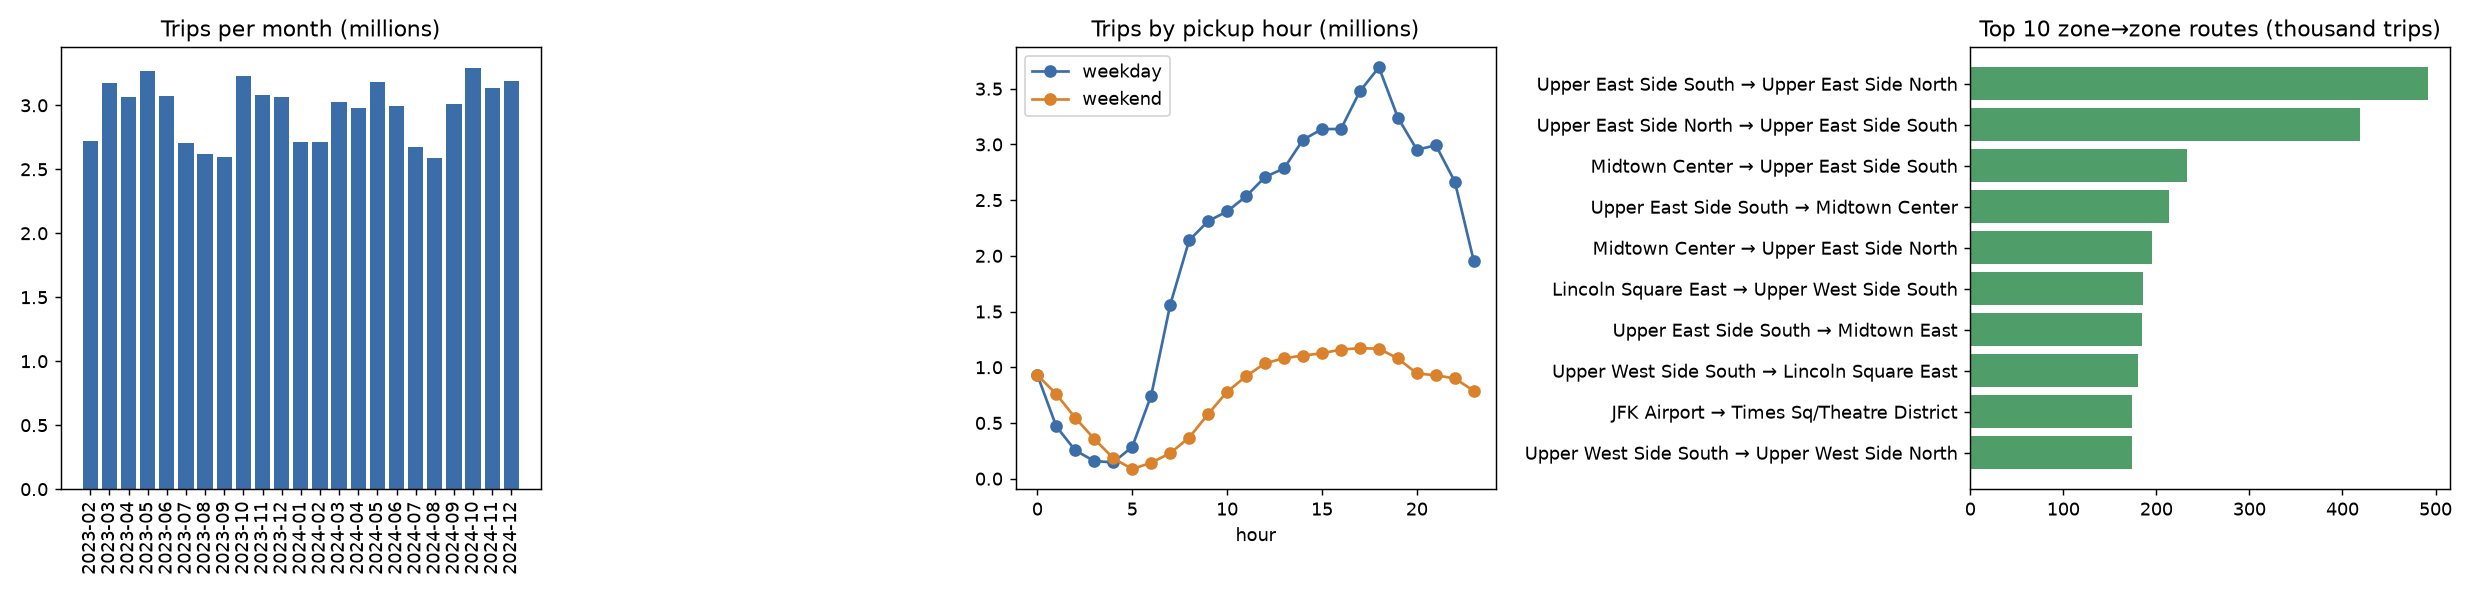

* 68,077,034 clean trips; total revenue $1.97B; average fare $19.77
* busiest pickup hour: 18:00; busiest month: 2024-10 (3,289,313 trips)
* top route: Upper East Side South → Upper East Side North (491,423 trips)
* average speed by time of day (mph): {'evening_rush': 9.9, 'late_night': 15.2, 'midday': 9.7, 'morning_rush': 12.0, 'night': 12.7}
* airport vs other:
        dest_type    trips  avg_fare  avg_miles  avg_minutes  avg_tip_pct
airport drop-off  1706990     59.98      13.69         39.5         24.1
           other 66370044     18.73       3.22         16.2         25.3
* tipping (credit card, avg tip % of fare):
  time_of_day  is_weekend  card_trips  avg_tip_pct  median_tip_pct
evening_rush       False    11441119        27.42           27.98
  late_night        True     2492467        25.98           25.88
       night       False     9108937        25.82           26.28

=== timing summary ===


,step,seconds
0,1. raw row count,0.61
1,3. lazy: 9 transformations,0.03
2,3. eager: collect(),2.37
3,"4. write curated_trips (partitionBy, no shuffle)",196.66
4,4. write aggregates/monthly,25.76
5,4. write aggregates/borough_time_of_day,22.94
6,4. write aggregates/hourly,19.09
7,4. write aggregates/top_routes,12.66
8,4. write aggregates/top_zones_per_borough,12.02
9,5. curated row count (read-back check),0.34


Spark stopped. Event log: local-1795029536797


In [23]:
m = pd.read_parquet(f"{OUT}/aggregates/monthly").sort_values("year_month")
h = pd.read_parquet(f"{OUT}/aggregates/hourly")
r = pd.read_parquet(f"{OUT}/aggregates/top_routes").sort_values("trips", ascending=False)
bt = pd.read_parquet(f"{OUT}/aggregates/borough_time_of_day")

fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
ax[0].bar(m.year_month, m.trips / 1e6, color="#3b6ea8"); ax[0].set_title("Trips per month (millions)")
ax[0].tick_params(axis="x", rotation=90)
for wk, c in [(False, "#3b6ea8"), (True, "#d9822b")]:
    d = h[h.is_weekend == wk].sort_values("pickup_hour"); ax[1].plot(d.pickup_hour, d.trips / 1e6, marker="o", color=c, label="weekend" if wk else "weekday")
ax[1].set_title("Trips by pickup hour (millions)"); ax[1].set_xlabel("hour"); ax[1].legend()
ax[2].barh((r.pu_zone + " → " + r.do_zone).head(10)[::-1], r.trips.head(10)[::-1] / 1e3, color="#4f9d69"); ax[2].set_title("Top 10 zone→zone routes (thousand trips)")
plt.tight_layout(); plt.savefig(f"{IMG}/key_findings.png", dpi=130); plt.close()
display(Image(f"{IMG}/key_findings.png"))

busiest = h.groupby("pickup_hour").trips.sum().idxmax()
slow = bt.groupby("time_of_day").apply(lambda d: (d.avg_speed_mph * d.trips).sum() / d.trips.sum()).round(1)
print(f"* {cur_rows:,} clean trips; total revenue ${m.revenue.sum()/1e9:.2f}B; average fare ${(m.avg_fare*m.trips).sum()/m.trips.sum():.2f}")
print(f"* busiest pickup hour: {busiest}:00; busiest month: {m.loc[m.trips.idxmax(), 'year_month']} ({m.trips.max():,} trips)")
print(f"* top route: {r.iloc[0].pu_zone} → {r.iloc[0].do_zone} ({r.iloc[0].trips:,} trips)")
print("* average speed by time of day (mph):", slow.to_dict())
print("* airport vs other:\n", sql4.to_string(index=False))
print("* tipping (credit card, avg tip % of fare):\n", sql3.head(3).to_string(index=False))

print("\n=== timing summary ===")
display(pd.DataFrame(results, columns=["step", "seconds"]).round(2))
pd.DataFrame(results, columns=["step", "seconds"]).round(2).to_csv(f"{OUT}/timings.csv", index=False)
APP_ID = sc.applicationId
open(f"{OUT}/app_id.txt", "w").write(APP_ID)
spark.stop()          # flushes the event log so the History Server can display the SQL "Query Details" pages
print("Spark stopped. Event log:", APP_ID)